# Cảnh báo bất thường — ETS + robust z (xuất khẩu)

Prototype phát hiện anomaly trên chuỗi tháng xuất/nhập khẩu. **Toàn bộ logic nằm trong notebook này.**

**Ý tưởng chính**
- Tại tháng $t$, chỉ dùng dữ liệu $\leq t-1$ để dự báo tháng $t$ (**không nhìn tương lai**).
- Chuẩn hóa sai số bằng **MAD** → **robust z-score** → cấp cảnh báo OK / WARN / CRITICAL.

**Chỉ tiêu:** `so_luong`, `tri_gia`, `don_gia = tri_gia / so_luong`

**Các bước**
1. Cấu hình tham số (warm-up, cửa sổ, ngưỡng)
2. Định nghĩa hàm lõi (load → forecast → z → alert → synthetic recall)
3. Demo một chuỗi (mặc định: gạo) + biểu đồ
4. Batch 4 chuỗi XK → `reports/alert_backtest/`

> Quan sát 4 chuỗi: [`scripts/ets_tier1_explore.ipynb`](scripts/ets_tier1_explore.ipynb)  
> Giải thích chi tiết: [`docs/rice_alert_prototype.md`](docs/rice_alert_prototype.md)


## 1. Cấu hình & thư viện

- `MIN_TRAIN`: số tháng tối thiểu trước khi bắt đầu score
- `WINDOW` / `SCALE_WIN`: cửa sổ fit ETS và ước lượng MAD
- `WARN` / `CRIT`: ngưỡng |z|


In [1]:
from __future__ import annotations

import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.titlesize"] = 12

# Tham số pipeline ETS + robust z
DATA_PATH = Path("data/csv/xuat_khau/gạo.csv")
MIN_TRAIN = 60
WINDOW = 96
SCALE_WIN = 36
WARN, CRIT = 3.0, 4.5
INJECT_FACTORS = [1.2, 1.5, 2.0, 3.0, 0.7, 0.5, 0.3]

BATCH_FILES = [
    "data/csv/xuat_khau/gạo.csv",
    "data/csv/xuat_khau/sắt thép các loại.csv",
    "data/csv/xuat_khau/xăng dầu các loại.csv",
    "data/csv/xuat_khau/dầu thô.csv",
]
OUT_DIR = Path("reports/alert_backtest")

print(f"Data demo: {DATA_PATH.resolve()}")
print(f"MIN_TRAIN={MIN_TRAIN}, WINDOW={WINDOW}, SCALE_WIN={SCALE_WIN}")
print(f"Ngưỡng: WARN |z|>={WARN}, CRITICAL |z|>={CRIT}")
print(f"OUT_DIR={OUT_DIR}")


Data demo: C:\Homework\Code File\ML docs\Anomaly Detection\data\csv\xuat_khau\gạo.csv
MIN_TRAIN=60, WINDOW=96, SCALE_WIN=36
Ngưỡng: WARN |z|>=3.0, CRITICAL |z|>=4.5
OUT_DIR=reports\alert_backtest


## 2. Hàm lõi (load → forecast → recall → run_series)

Các hàm dưới đây là **toàn bộ logic** pipeline. Demo và batch đều gọi lại chúng.
Không còn phụ thuộc script `.py` riêng.


In [2]:
def load(path: str | Path) -> pd.DataFrame:
    df = pd.read_csv(path, parse_dates=["thang_nam"]).set_index("thang_nam").sort_index()
    df = df.asfreq("MS")
    df["don_gia"] = df["tri_gia"] / df["so_luong"]
    return df


def one_step_forecast(y: pd.Series):
    """y: log-series (MS). Trả về (yhat, err, scale, z)."""
    idx, yhat = [], []
    for t in range(MIN_TRAIN, len(y)):
        hist = y.iloc[max(0, t - WINDOW) : t]
        try:
            m = ExponentialSmoothing(
                hist,
                trend="add",
                damped_trend=True,
                seasonal="add",
                seasonal_periods=12,
            ).fit()
            f = float(m.forecast(1).iloc[0])
        except Exception:
            f = float(hist.iloc[-12:].mean())
        idx.append(y.index[t])
        yhat.append(f)
    yhat = pd.Series(yhat, index=idx)
    err = y.loc[yhat.index] - yhat
    med = err.shift(1).rolling(SCALE_WIN, min_periods=12).median()
    mad = (err.shift(1) - med).abs().rolling(SCALE_WIN, min_periods=12).median()
    scale = (mad / 0.6745).clip(lower=1e-3)
    z = (err - med) / scale
    return yhat, err, scale, z


def synthetic_recall(y: pd.Series, yhat: pd.Series, err: pd.Series, scale: pd.Series) -> dict:
    ok = scale.notna()
    med = err.shift(1).rolling(SCALE_WIN, min_periods=12).median()
    out = {}
    for f in INJECT_FACTORS:
        z_inj = (y + np.log(f) - yhat - med) / scale
        out[f"x{f}"] = round(float((z_inj[ok].abs() >= WARN).mean()), 3)
    return out


def run_series(path: str | Path, out_dir: Path = OUT_DIR) -> dict:
    """Backtest 1 chuỗi → CSV + summary JSON trong out_dir."""
    path = Path(path)
    df = load(path)
    out = pd.DataFrame(index=df.index[MIN_TRAIN:])
    res = {}
    recall = {}

    for col in ["so_luong", "tri_gia", "don_gia"]:
        y = np.log(df[col].astype(float)).replace([np.inf, -np.inf], np.nan)
        if y.isna().all():
            continue
        y_fit = y.ffill().bfill()
        yhat, err, scale, z = one_step_forecast(y_fit)
        out[f"z_{col}"] = z
        res[col] = {"y": y_fit, "yhat": yhat, "err": err, "scale": scale, "z": z}
        if col in ("so_luong", "tri_gia"):
            recall[col] = synthetic_recall(y_fit.loc[yhat.index], yhat, err, scale)

    z_cols = [c for c in ["z_so_luong", "z_tri_gia", "z_don_gia"] if c in out.columns]
    zs = out[z_cols].abs()
    n_warn = (zs >= WARN).sum(axis=1)
    out["alert"] = np.where(
        (n_warn >= 2) | (zs.max(axis=1) >= CRIT),
        "CRITICAL",
        np.where(n_warn >= 1, "WARN", "OK"),
    )
    out["drivers"] = zs.apply(
        lambda r: ",".join(k[2:] for k, v in r.items() if v >= WARN),
        axis=1,
    )

    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    stem = path.stem
    csv_path = out_dir / f"{stem}_alert_backtest.csv"
    out.to_csv(csv_path)

    by_year = out.groupby([out.index.year, "alert"]).size().unstack(fill_value=0).to_dict()
    alert_counts = out["alert"].value_counts().to_dict()
    critical_months = (
        out[out.alert == "CRITICAL"][z_cols + ["drivers"]].round(2).reset_index()
    )
    critical_months["thang_nam"] = critical_months["thang_nam"].astype(str)
    n_years = max(1, out.index.year.nunique())
    alerts_per_year = {
        "WARN": round(int(alert_counts.get("WARN", 0)) / n_years, 2),
        "CRITICAL": round(int(alert_counts.get("CRITICAL", 0)) / n_years, 2),
        "WARN_or_CRITICAL": round(
            (int(alert_counts.get("WARN", 0)) + int(alert_counts.get("CRITICAL", 0))) / n_years,
            2,
        ),
    }

    summary = {
        "series": stem,
        "source": str(path).replace("\\", "/"),
        "n_months_scored": int(len(out)),
        "date_start": str(out.index.min().date()) if len(out) else None,
        "date_end": str(out.index.max().date()) if len(out) else None,
        "alert_counts": {k: int(v) for k, v in alert_counts.items()},
        "alerts_per_year": alerts_per_year,
        "by_year": {str(k): {str(a): int(c) for a, c in v.items()} for k, v in by_year.items()},
        "critical_months": critical_months.to_dict(orient="records"),
        "synthetic_recall": recall,
        "csv": str(csv_path).replace("\\", "/"),
    }
    (out_dir / f"{stem}_summary.json").write_text(
        json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    return summary, out, res, df

print("Đã định nghĩa: load, one_step_forecast, synthetic_recall, run_series")


Đã định nghĩa: load, one_step_forecast, synthetic_recall, run_series, write_comparison_report


## 3. Demo một chuỗi (mặc định: gạo) — chạy pipeline

Gọi `run_series` → summary + bảng backtest + kết quả forecast.


In [3]:
summary, out, res, df = run_series(DATA_PATH, out_dir=OUT_DIR)
print(f"Khoảng thời gian: {df.index.min().date()} → {df.index.max().date()} | n={len(df)}")
print("Alerts:", summary["alert_counts"])
print("Alerts/year:", summary["alerts_per_year"])
print("Saved:", summary["csv"])
df[["so_luong", "tri_gia", "don_gia"]].describe().round(2)


Khoảng thời gian: 2009-01-01 → 2026-08-01 | n=212
Alerts: {'OK': 150, 'CRITICAL': 1, 'WARN': 1}
Alerts/year: {'WARN': 0.08, 'CRITICAL': 0.08, 'WARN_or_CRITICAL': 0.15}
Saved: reports/alert_backtest/gạo_alert_backtest.csv


,so_luong,tri_gia,don_gia
count,212.00,2.120000e+02,212.00
mean,572920.29,2.819757e+08,489.78
std,183408.53,1.025955e+08,59.52
min,170488.00,7.432747e+07,371.01
25%,446927.75,2.098986e+08,446.66
50%,546970.00,2.679486e+08,481.84
75%,677394.75,3.381410e+08,517.14
max,1121662.00,7.080423e+08,695.30


### 3.1. Trực quan hóa chuỗi gốc

Ba chỉ tiêu mức gốc theo thời gian — nền để đối chiếu tháng bị cảnh báo sau này.


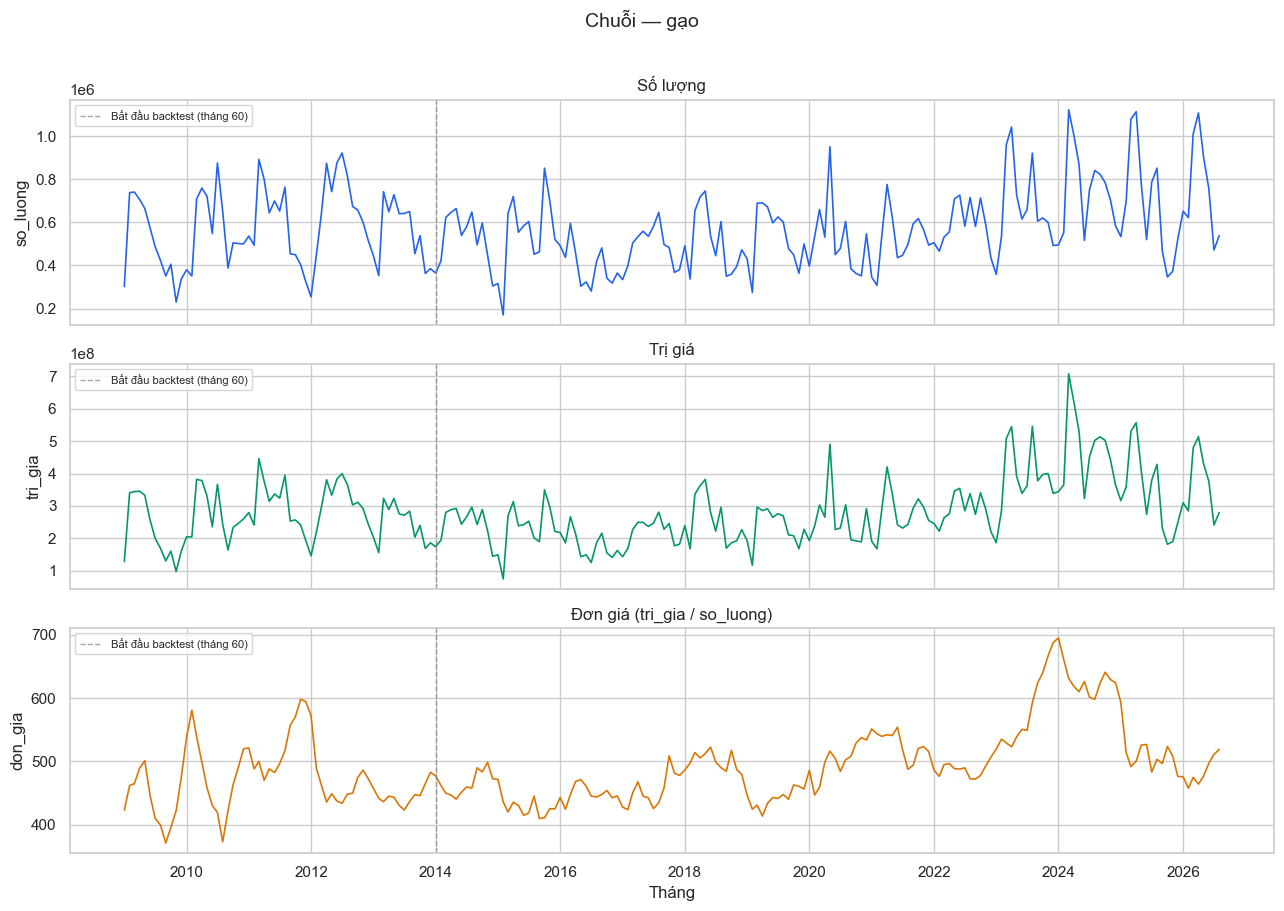

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, col, color, title in zip(
    axes,
    ["so_luong", "tri_gia", "don_gia"],
    ["#2563eb", "#059669", "#d97706"],
    ["Số lượng", "Trị giá", "Đơn giá (tri_gia / so_luong)"],
):
    ax.plot(df.index, df[col], color=color, lw=1.2)
    ax.set_ylabel(col)
    ax.set_title(title)
    ax.axvline(df.index[MIN_TRAIN], color="gray", ls="--", lw=1, alpha=0.7,
               label=f"Bắt đầu backtest (tháng {MIN_TRAIN})")
    ax.legend(loc="upper left", fontsize=8)
axes[-1].set_xlabel("Tháng")
fig.suptitle(f"Chuỗi — {DATA_PATH.stem}", fontsize=14, y=1.01)
fig.tight_layout()
plt.show()


## 4. Thực tế vs dự báo (thang log)

So `y` (log) với one-step `yhat` từ ETS — residual lớn sẽ đẩy |z| lên.


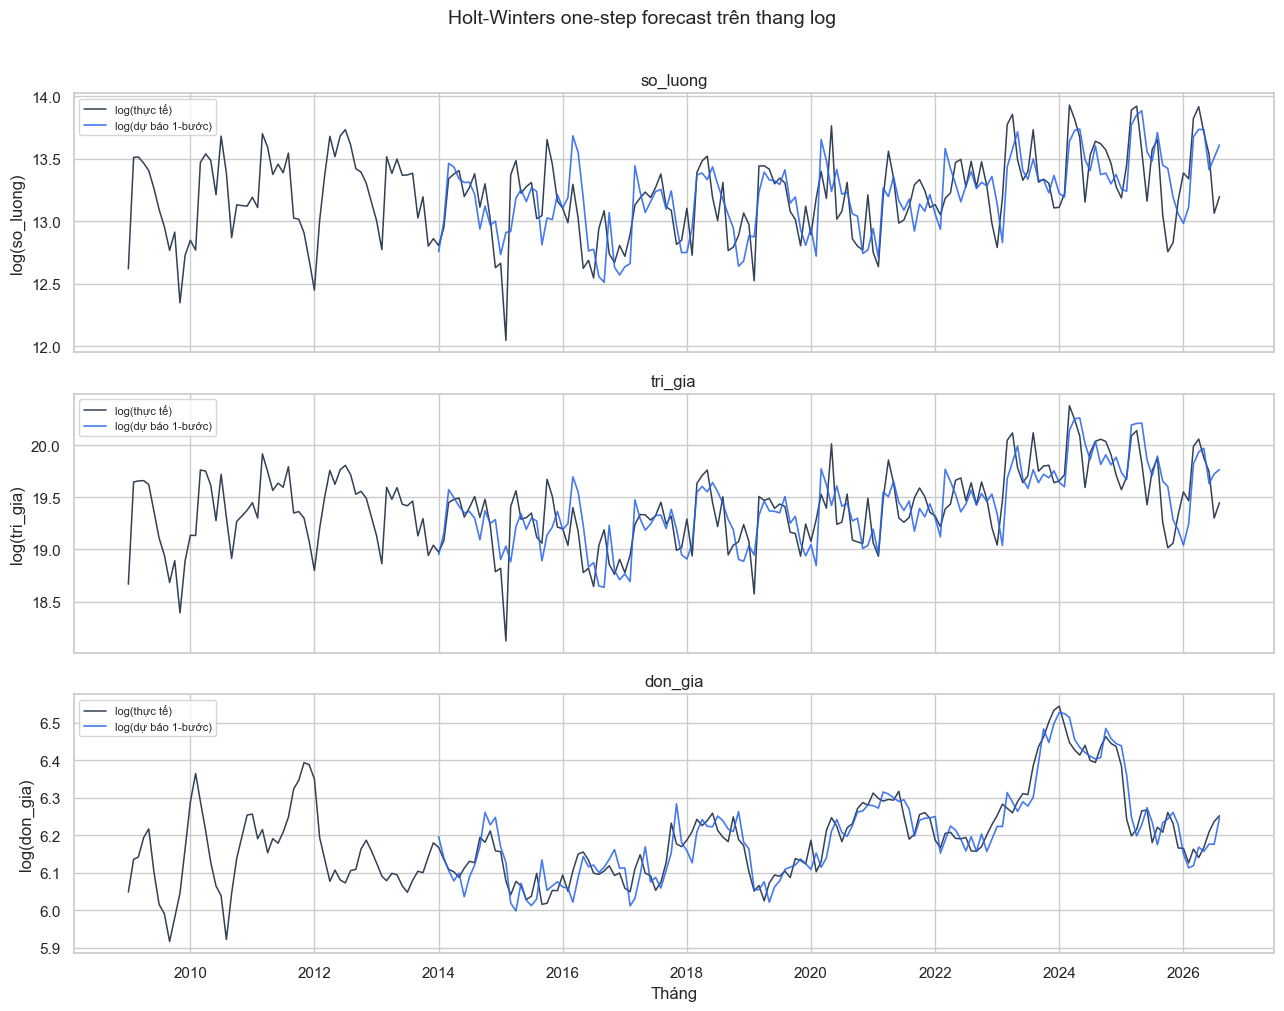

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
for ax, col in zip(axes, ["so_luong", "tri_gia", "don_gia"]):
    if col not in res:
        continue
    y, yhat = res[col]["y"], res[col]["yhat"]
    ax.plot(y.index, y, color="#334155", lw=1.1, label="log(thực tế)")
    ax.plot(yhat.index, yhat, color="#2563eb", lw=1.2, alpha=0.85, label="log(dự báo 1-bước)")
    ax.set_ylabel(f"log({col})")
    ax.set_title(col)
    ax.legend(loc="upper left", fontsize=8)
axes[-1].set_xlabel("Tháng")
fig.suptitle("Holt-Winters one-step forecast trên thang log", fontsize=14, y=1.01)
fig.tight_layout()
plt.show()


## 5. Residual & robust z-score

Trái: residual; phải: z đã chuẩn hóa MAD. Vượt WARN/CRIT → ứng viên cảnh báo theo chỉ tiêu.


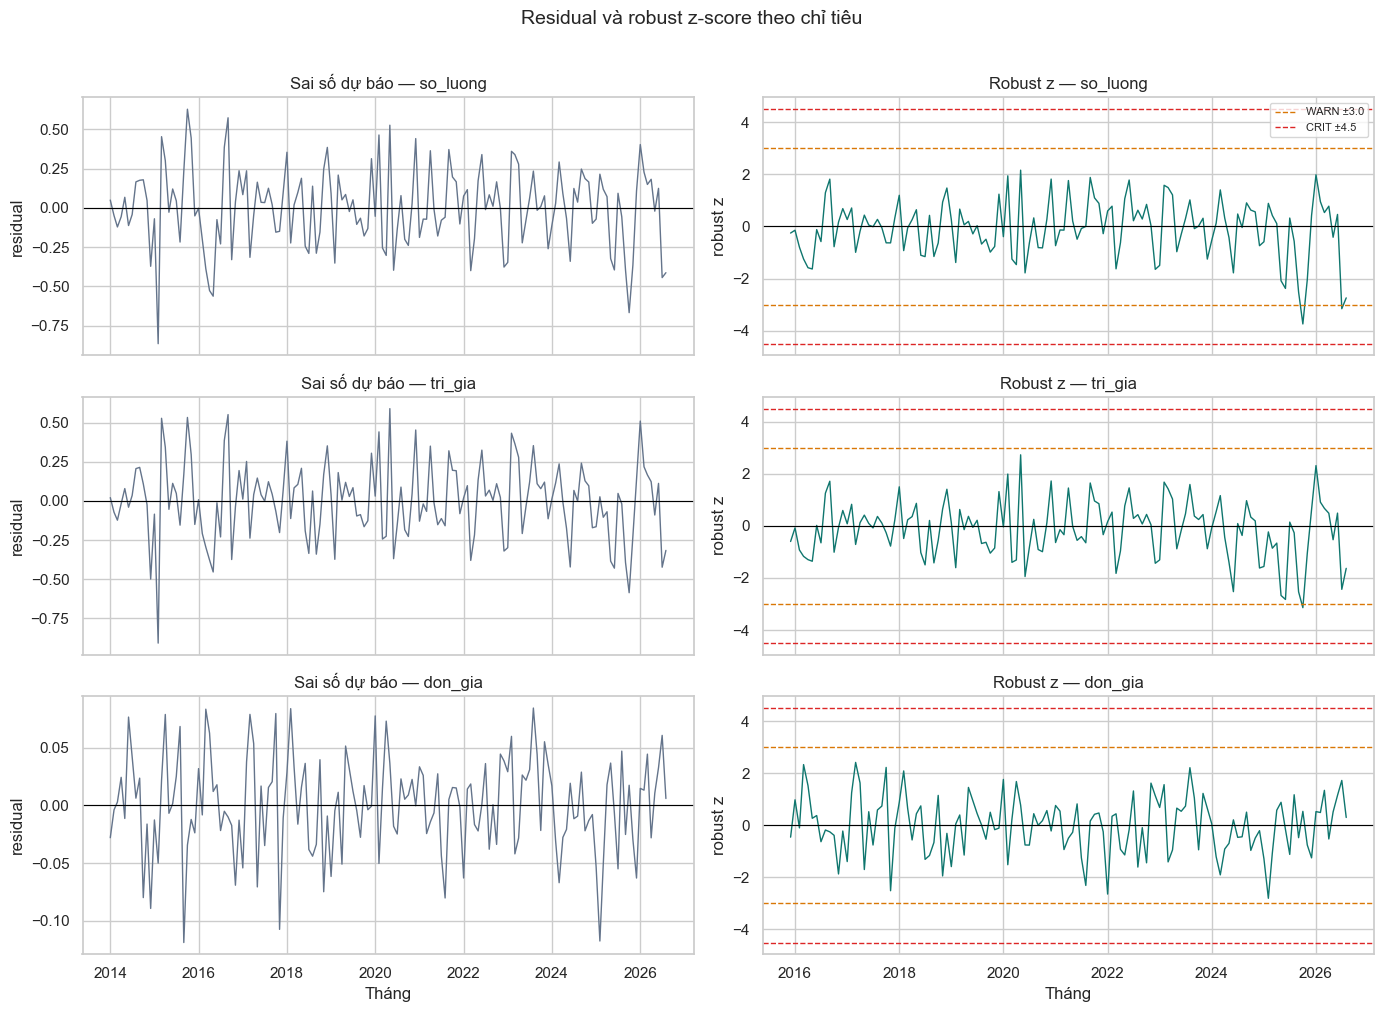

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex="col")
for i, col in enumerate(["so_luong", "tri_gia", "don_gia"]):
    if col not in res:
        continue
    err, z = res[col]["err"], res[col]["z"]
    axes[i, 0].plot(err.index, err, color="#64748b", lw=1)
    axes[i, 0].axhline(0, color="black", lw=0.8)
    axes[i, 0].set_ylabel("residual")
    axes[i, 0].set_title(f"Sai số dự báo — {col}")
    axes[i, 1].plot(z.index, z, color="#0f766e", lw=1)
    axes[i, 1].axhline(WARN, color="#d97706", ls="--", lw=1, label=f"WARN ±{WARN}")
    axes[i, 1].axhline(-WARN, color="#d97706", ls="--", lw=1)
    axes[i, 1].axhline(CRIT, color="#dc2626", ls="--", lw=1, label=f"CRIT ±{CRIT}")
    axes[i, 1].axhline(-CRIT, color="#dc2626", ls="--", lw=1)
    axes[i, 1].axhline(0, color="black", lw=0.8)
    axes[i, 1].set_ylabel("robust z")
    axes[i, 1].set_title(f"Robust z — {col}")
    if i == 0:
        axes[i, 1].legend(loc="upper right", fontsize=8)
axes[-1, 0].set_xlabel("Tháng")
axes[-1, 1].set_xlabel("Tháng")
fig.suptitle("Residual và robust z-score theo chỉ tiêu", fontsize=14, y=1.01)
fig.tight_layout()
plt.show()


## 6. Bản đồ cảnh báo trên chuỗi gốc

Gộp rule đa chỉ tiêu: 1 chỉ tiêu vượt WARN → WARN; ≥2 hoặc một CRITICAL → CRITICAL.


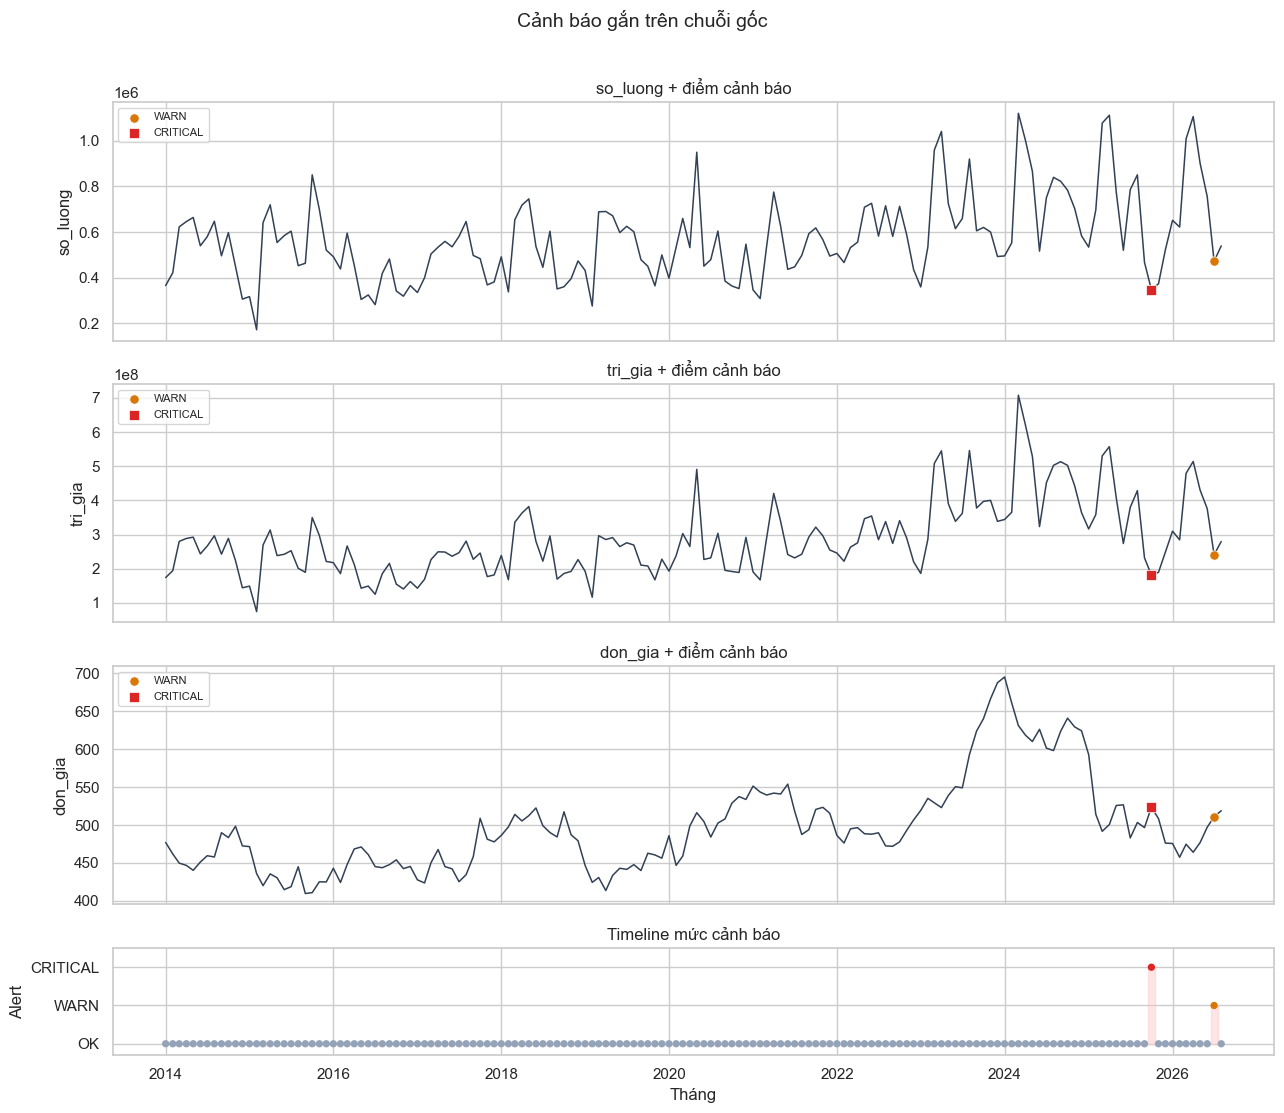

In [7]:
alert_color = {"OK": "#94a3b8", "WARN": "#d97706", "CRITICAL": "#dc2626"}
fig, axes = plt.subplots(4, 1, figsize=(13, 11), sharex=True,
                         gridspec_kw={"height_ratios": [1, 1, 1, 0.45]})
for ax, col in zip(axes[:3], ["so_luong", "tri_gia", "don_gia"]):
    series = df[col].loc[out.index]
    ax.plot(series.index, series, color="#334155", lw=1.1)
    for level, marker, size in [("WARN", "o", 45), ("CRITICAL", "s", 55)]:
        mask = out["alert"] == level
        ax.scatter(
            out.index[mask], series.loc[out.index[mask]],
            c=alert_color[level], s=size, marker=marker,
            zorder=5, label=level, edgecolors="white", linewidths=0.5,
        )
    ax.set_ylabel(col)
    ax.set_title(f"{col} + điểm cảnh báo")
    ax.legend(loc="upper left", fontsize=8)
level_map = {"OK": 0, "WARN": 1, "CRITICAL": 2}
levels = out["alert"].map(level_map)
axes[3].fill_between(out.index, 0, levels, step="mid", color="#fecaca", alpha=0.5)
axes[3].scatter(out.index, levels, c=out["alert"].map(alert_color), s=18, zorder=3)
axes[3].set_yticks([0, 1, 2])
axes[3].set_yticklabels(["OK", "WARN", "CRITICAL"])
axes[3].set_ylim(-0.3, 2.5)
axes[3].set_ylabel("Alert")
axes[3].set_xlabel("Tháng")
axes[3].set_title("Timeline mức cảnh báo")
fig.suptitle("Cảnh báo gắn trên chuỗi gốc", fontsize=14, y=1.01)
fig.tight_layout()
plt.show()


## 7. Heatmap |z| theo năm × tháng

Nhìn mùa vụ / cụm tháng có |z| cao trên từng chỉ tiêu.


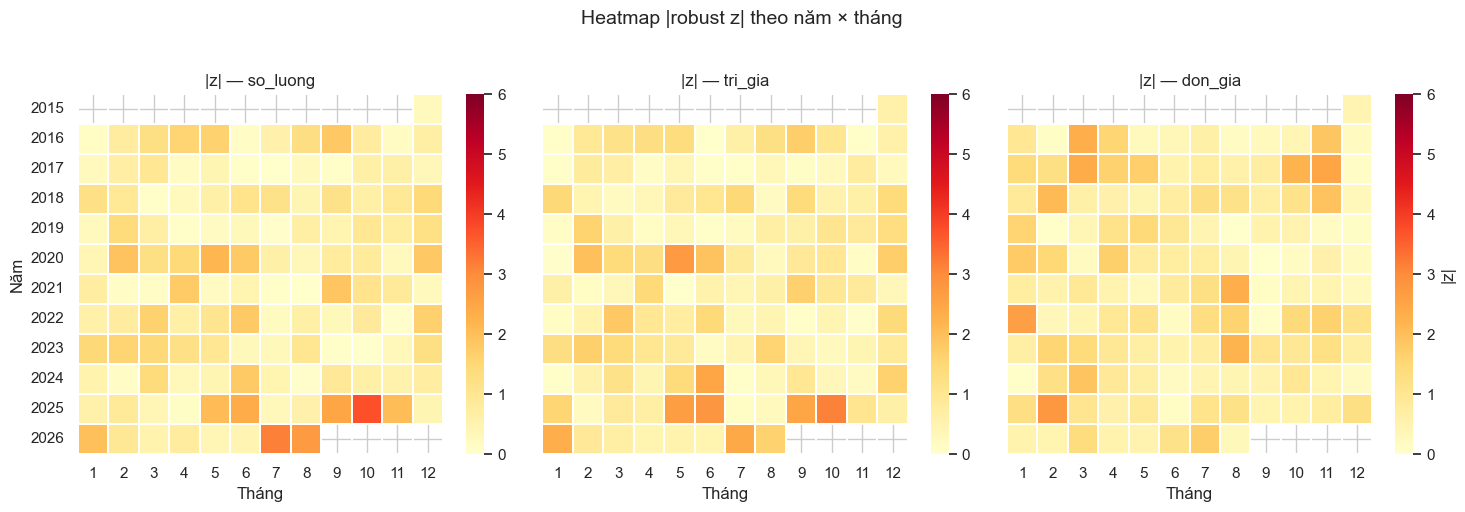

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, col in zip(axes, ["so_luong", "tri_gia", "don_gia"]):
    if col not in res:
        continue
    z = res[col]["z"].dropna()
    pivot = (
        z.abs().to_frame("abs_z")
        .assign(year=lambda d: d.index.year, month=lambda d: d.index.month)
        .pivot(index="year", columns="month", values="abs_z")
    )
    sns.heatmap(
        pivot, ax=ax, cmap="YlOrRd", vmin=0, vmax=6,
        linewidths=0.3, linecolor="white",
        cbar_kws={"label": "|z|"} if col == "don_gia" else None,
    )
    ax.set_title(f"|z| — {col}")
    ax.set_xlabel("Tháng")
    ax.set_ylabel("Năm" if col == "so_luong" else "")
fig.suptitle("Heatmap |robust z| theo năm × tháng", fontsize=14, y=1.02)
fig.tight_layout()
plt.show()


## 8. Tóm tắt cảnh báo

Đếm theo năm và liệt kê tháng CRITICAL kèm drivers.


=== Số cảnh báo theo năm ===


alert,CRITICAL,OK,WARN
thang_nam,,,
2014,0,12,0
2015,0,12,0
2016,0,12,0
2017,0,12,0
2018,0,12,0
2019,0,12,0
2020,0,12,0
2021,0,12,0
2022,0,12,0


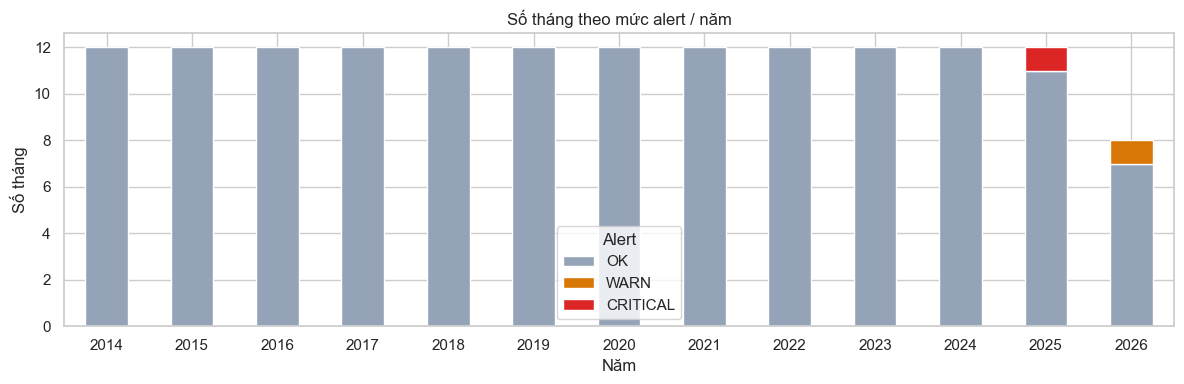

=== CRITICAL ===


,z_so_luong,z_tri_gia,z_don_gia,drivers
thang_nam,,,,
2025-10-01,-3.7,-3.1,0.5,"so_luong,tri_gia"


=== WARN ===


,z_so_luong,z_tri_gia,z_don_gia,drivers
thang_nam,,,,
2026-07-01,-3.2,-2.4,1.7,so_luong


Synthetic recall: {'so_luong': {'x1.2': 0.0, 'x1.5': 0.116, 'x2.0': 0.426, 'x3.0': 0.876, 'x0.7': 0.101, 'x0.5': 0.457, 'x0.3': 0.953}, 'tri_gia': {'x1.2': 0.016, 'x1.5': 0.116, 'x2.0': 0.45, 'x3.0': 0.915, 'x0.7': 0.116, 'x0.5': 0.496, 'x0.3': 0.961}}


In [9]:
print("=== Số cảnh báo theo năm ===")
by_year = out.groupby([out.index.year, "alert"]).size().unstack(fill_value=0)
display(by_year)

fig, ax = plt.subplots(figsize=(12, 4))
by_year.reindex(columns=["OK", "WARN", "CRITICAL"], fill_value=0).plot(
    kind="bar", stacked=True, ax=ax,
    color=[alert_color["OK"], alert_color["WARN"], alert_color["CRITICAL"]],
)
ax.set_title("Số tháng theo mức alert / năm")
ax.set_xlabel("Năm")
ax.set_ylabel("Số tháng")
ax.legend(title="Alert")
plt.xticks(rotation=0)
fig.tight_layout()
plt.show()

print("=== CRITICAL ===")
display(out[out.alert == "CRITICAL"][["z_so_luong", "z_tri_gia", "z_don_gia", "drivers"]].round(1))
print("=== WARN ===")
display(out[out.alert == "WARN"][["z_so_luong", "z_tri_gia", "z_don_gia", "drivers"]].round(1))
print("Synthetic recall:", summary["synthetic_recall"])


## 9. Đánh giá giả lập (synthetic injection)

Nhân mức bằng các hệ số → đo recall khi |z| ≥ WARN. Dùng để so với Chronos / IF sau này.


,x1.2,x1.5,x2.0,x3.0,x0.7,x0.5,x0.3
so_luong,0.000,0.116,0.426,0.876,0.101,0.457,0.953
tri_gia,0.016,0.116,0.450,0.915,0.116,0.496,0.961


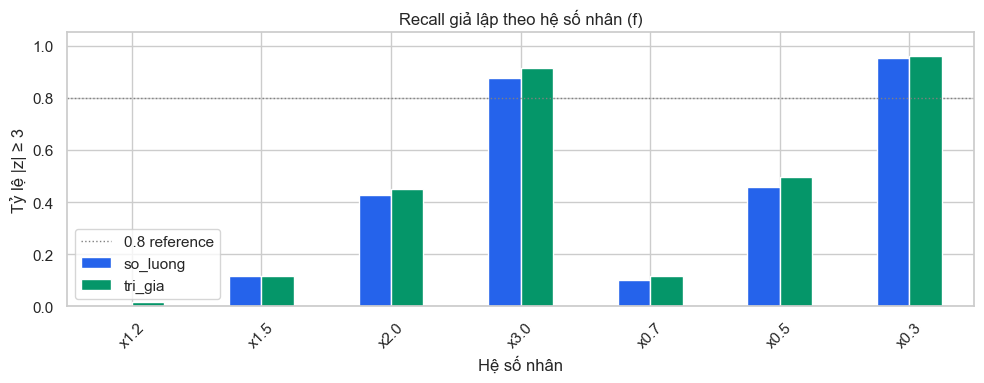

In [10]:
recall_df = pd.DataFrame(summary["synthetic_recall"]).T
# rows may be metrics; ensure factor columns
display(recall_df)

fig, ax = plt.subplots(figsize=(10, 4))
recall_df.T.plot(kind="bar", ax=ax, color=["#2563eb", "#059669"])
ax.axhline(0.8, color="gray", ls=":", lw=1, label="0.8 reference")
ax.set_title("Recall giả lập theo hệ số nhân (f)")
ax.set_xlabel("Hệ số nhân")
ax.set_ylabel("Tỷ lệ |z| ≥ 3")
ax.set_ylim(0, 1.05)
ax.legend()
plt.xticks(rotation=45)
fig.tight_layout()
plt.show()


## 10. Batch 4 chuỗi XK

Đặt `RUN_BATCH = True` rồi chạy cell dưới để ghi
`reports/alert_backtest/*_summary.json` và `*_alert_backtest.csv`.

Bảng so sánh alerts/năm hiển thị **trong notebook** (cell dưới) và/hoặc
mở `scripts/ets_tier1_explore.ipynb`. Không generate file `.md` bằng code.


In [12]:
# Đặt RUN_BATCH = True rồi chạy cell này để regenerate backtest 4 chuỗi
RUN_BATCH = False

if RUN_BATCH:
    summaries = []
    for p in BATCH_FILES:
        print(f"Running {p} ...")
        s, *_ = run_series(p, out_dir=OUT_DIR)
        print("Alerts:", s["alert_counts"], "| /năm:", s["alerts_per_year"])
        print("CRITICAL:", s["critical_months"])
        summaries.append(s)

    cmp = pd.DataFrame(
        [
            {
                "series": s["series"],
                "WARN/năm": s["alerts_per_year"]["WARN"],
                "CRITICAL/năm": s["alerts_per_year"]["CRITICAL"],
                "WARN+CRIT/năm": s["alerts_per_year"]["WARN_or_CRITICAL"],
                "n_WARN": s["alert_counts"].get("WARN", 0),
                "n_CRITICAL": s["alert_counts"].get("CRITICAL", 0),
                "n_scored": s["n_months_scored"],
            }
            for s in summaries
        ]
    ).set_index("series")
    display(cmp)
    print(f"Đã ghi summary/CSV vào {OUT_DIR}")
else:
    print("RUN_BATCH=False — bỏ qua. Đổi thành True để chạy batch 4 chuỗi.")
    print(f"Xem kết quả đã có: {OUT_DIR} hoặc scripts/ets_tier1_explore.ipynb")


RUN_BATCH=False — bỏ qua. Đổi thành True để chạy batch 4 chuỗi.
Báo cáo hiện có (nếu đã chạy trước): reports\alert_backtest\ets_tier1_comparison.md
